In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', None)

In [17]:
# #original df
# train_df = pd.read_csv('train.csv')
# test_df = pd.read_csv('test.csv')

# print(train_df.shape, test_df.shape)

#FE df

# train_df = pd.read_csv('full_fe_df.csv')
# test_df = pd.read_csv('full_fe_df_test.csv')

#Simplified FE df

train_df = pd.read_csv('simplified_fe_df.csv')
test_df = pd.read_csv('simplified_fe_df_test.csv')

In [18]:
target = 'satisfaction'
cat_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

train_df[target] = train_df[target].astype(int)

for col in cat_cols:
    cats = sorted(train_df[col].unique())
    train_df[col] = pd.Categorical(train_df[col], categories=cats)
    test_df[col] = pd.Categorical(test_df[col], categories=cats)

X = train_df.drop(columns=['id', target])
y = train_df[target]
X_test = test_df.drop(columns=['id'])[X.columns]

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_val.shape, X_test.shape)

(559708, 28) (139927, 28) (299844, 28)


In [20]:
model = LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=63,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    objective='binary',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric='auc',
    categorical_feature=cat_cols,
    callbacks=[early_stopping(50), log_evaluation(100)]
)

print("Best iteration:", model.best_iteration_)

Training until validation scores don't improve for 50 rounds
[100]	valid_0's auc: 0.95563	valid_0's binary_logloss: 0.238058
[200]	valid_0's auc: 0.956608	valid_0's binary_logloss: 0.235982
[300]	valid_0's auc: 0.956695	valid_0's binary_logloss: 0.235686
[400]	valid_0's auc: 0.956795	valid_0's binary_logloss: 0.235517
[500]	valid_0's auc: 0.956855	valid_0's binary_logloss: 0.23542
Early stopping, best iteration is:
[520]	valid_0's auc: 0.956878	valid_0's binary_logloss: 0.235398
Best iteration: 520


Validation ROC AUC Score: 0.9569


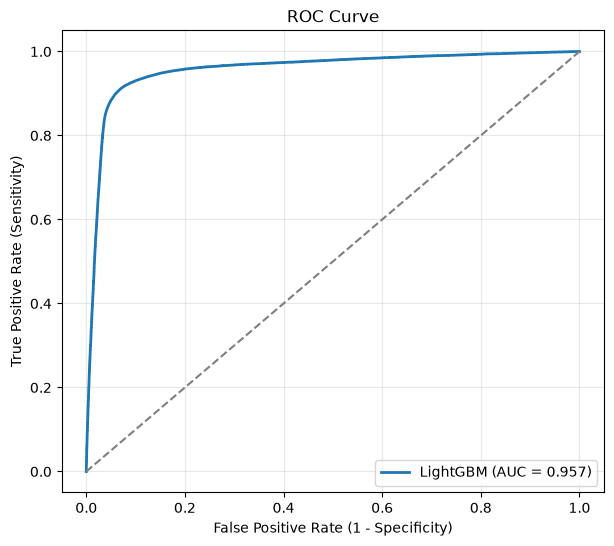

In [21]:
y_val_probs = model.predict_proba(X_val)[:, 1]

auc_score = roc_auc_score(y_val, y_val_probs)
print(f"Validation ROC AUC Score: {auc_score:.4f}")

fpr, tpr, thresholds = roc_curve(y_val, y_val_probs)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='tab:blue', lw=2, label=f'LightGBM (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='tab:gray', linestyle='--')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

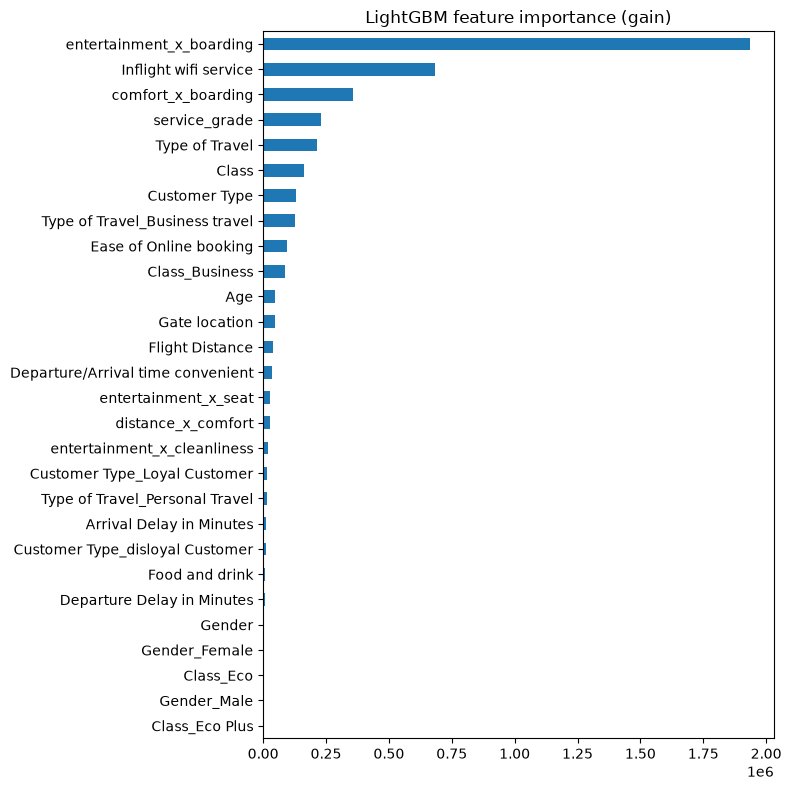

In [22]:
importances = pd.Series(model.booster_.feature_importance(importance_type='gain'), index=X.columns).sort_values()
importances.plot(kind='barh', figsize=(8, 8))
plt.title('LightGBM feature importance (gain)')
plt.tight_layout()
plt.show()

In [23]:
# import optuna
# from lightgbm import LGBMClassifier, early_stopping
# from sklearn.metrics import roc_auc_score

# def objective(trial):
#     params = {
#         'n_estimators': 2000,
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
#         'num_leaves': trial.suggest_int('num_leaves', 16, 256, log=True),
#         'max_depth': trial.suggest_int('max_depth', -1, 12),
#         'min_child_samples': trial.suggest_int('min_child_samples', 5, 200, log=True),
#         'subsample': trial.suggest_float('subsample', 0.5, 1.0),
#         'subsample_freq': 1,
#         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
#         'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
#         'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
#         'cat_smooth': trial.suggest_float('cat_smooth', 1.0, 50.0),
#         'objective': 'binary',
#         'random_state': 42,
#         'n_jobs': -1,
#         'verbose': -1
#     }
#     m = LGBMClassifier(**params)
#     m.fit(
#         X_train, y_train,
#         eval_set=[(X_val, y_val)],
#         eval_metric='auc',
#         categorical_feature=cat_cols,
#         callbacks=[early_stopping(50, verbose=False)]
#     )
#     trial.set_user_attr('best_iteration', m.best_iteration_)
#     return roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])

# study = optuna.create_study(
#     direction='maximize',
#     sampler=optuna.samplers.TPESampler(seed=42)
# )
# study.optimize(objective, n_trials=50, show_progress_bar=True)

# print("Best AUC:", study.best_value)
# print("Best params:", study.best_params)
# print("Best iteration:", study.best_trial.user_attrs['best_iteration'])


In [24]:
# import json

# to_save = {
#     **study.best_params,
#     'best_iteration': study.best_trial.user_attrs['best_iteration']
# }

# with open('best_lightgbm_fe_params.json', 'w') as f:
#     json.dump(to_save, f, indent=4)

In [25]:
import json

with open("best_lightgbm_fe_params.json") as f:
    best_lightgbm_fe_params = json.load(f)

print("Frozen LogReg params:")
for k, v in best_lightgbm_fe_params.items():
    print(f"  {k}: {v}")

Frozen LogReg params:
  learning_rate: 0.013622918036755749
  num_leaves: 130
  max_depth: 12
  min_child_samples: 49
  subsample: 0.8689282494342284
  colsample_bytree: 0.5531554032080875
  reg_alpha: 1.3434898332819496e-08
  reg_lambda: 3.398504316826567e-05
  cat_smooth: 41.3901217605434
  best_iteration: 1056


In [26]:
best_model = LGBMClassifier(
    **best_lightgbm_fe_params,
    n_estimators=best_lightgbm_fe_params['best_iteration'],
    subsample_freq=1,
    objective='binary',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
best_model.fit(X, y, categorical_feature=cat_cols)

,num_leaves,130
,max_depth,12
,learning_rate,0.013622918036755749
,n_estimators,1056
,objective,'binary'
,min_child_samples,49
,subsample,0.8689282494342284
,subsample_freq,1
,colsample_bytree,0.5531554032080875
,reg_alpha,1.3434898332819496e-08
,reg_lambda,3.398504316826567e-05


In [30]:
test_pred = model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({'id': test_df['id'], 'satisfaction': test_pred})
submission.to_csv('submission_lgbm_fe3.csv', index=False)
submission.head()

,id,satisfaction
0,699635,0.289402
1,699636,0.907772
2,699637,0.682010
3,699638,0.070778
4,699639,0.046748


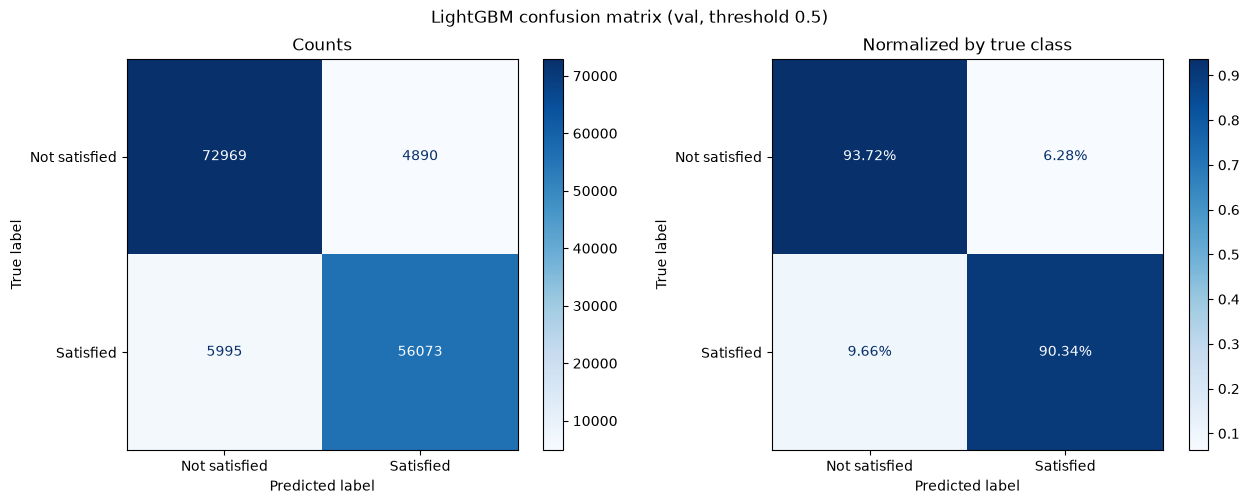

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

val_probs = model.predict_proba(X_val)[:, 1]
val_pred = (val_probs >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, norm, title in zip(axes, [None, 'true'], ['Counts', 'Normalized by true class']):
    ConfusionMatrixDisplay.from_predictions(
        y_val, val_pred, normalize=norm, display_labels=['Not satisfied', 'Satisfied'],
        cmap='Blues', values_format='d' if norm is None else '.2%', ax=ax
    )
    ax.set_title(title)
plt.suptitle('LightGBM confusion matrix (val, threshold 0.5)')
plt.tight_layout()
plt.show()

In [29]:
# low, high = 0.3, 0.7

# val_df = train_df.loc[X_val.index].copy()
# val_df['proba'] = val_probs
# val_df['pred'] = val_pred
# val_df['correct'] = (val_df['pred'] == val_df[target]).astype(int)

# undecisive_df = val_df[(val_df['proba'] >= low) & (val_df['proba'] <= high)].copy()

# print("Undecisive rows:", len(undecisive_df), f"({len(undecisive_df) / len(val_df):.2%} of val)")
# print("Accuracy inside band:", undecisive_df['correct'].mean().round(4))
# print("Accuracy outside band:", val_df.loc[~val_df.index.isin(undecisive_df.index), 'correct'].mean().round(4))
# print()
# print(undecisive_df[target].value_counts(normalize=True).round(4))
# undecisive_df.head()